# 06 TabNet

## Student-authored explanation

Write the method and result interpretation here in your own words.

In [ ]:
from pathlib import Path
import os
import subprocess
import sys

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent
if not (REPO / "src" / "data.py").exists():
    REPO = Path("/content/credit-card-fraud-detection")
    if not (REPO / "src" / "data.py").exists():
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/VanshSharmaPES/credit-card-fraud-detection.git",
             str(REPO)],
            check=True,
        )
os.chdir(REPO)
%pip install -q -r requirements/base.txt -r requirements/tabnet.txt
!python src/data.py
sys.path.insert(0, str(REPO / "src"))


In [1]:
import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from pytorch_tabnet.tab_model import TabNetClassifier

from data import FEATURES, ROOT, load_splits
from evaluate import evaluate_model, permutation_importance

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

(X_train, y_train, X_val, y_val, X_test, y_test,
 row_id_val, row_id_test, amount_val, amount_test) = load_splits()
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_val.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)
y_train_np = np.asarray(y_train, dtype=np.int64)
y_val_np = np.asarray(y_val, dtype=np.int64)
y_test_np = np.asarray(y_test, dtype=np.int64)

n_normal = int((y_train_np == 0).sum())
n_fraud = int((y_train_np == 1).sum())
class_weights = torch.tensor([1.0, n_normal / n_fraud], dtype=torch.float32)
tabnet = TabNetClassifier(n_d=8, n_a=8, n_steps=3, seed=SEED, verbose=10)

train_start = time.perf_counter()
tabnet.fit(
    X_train=X_train_np,
    y_train=y_train_np,
    eval_set=[(X_val_np, y_val_np)],
    eval_name=["valid"],
    eval_metric=["auc"],
    max_epochs=50,
    patience=10,
    batch_size=4096,
    virtual_batch_size=512,
    num_workers=0,
    drop_last=False,
    loss_fn=nn.CrossEntropyLoss(weight=class_weights),
)
train_seconds = time.perf_counter() - train_start

predict_start = time.perf_counter()
p_val = tabnet.predict_proba(X_val_np)[:, 1]
p_test = tabnet.predict_proba(X_test_np)[:, 1]
predict_seconds = time.perf_counter() - predict_start

(ROOT / "models").mkdir(exist_ok=True)
tabnet.save_model(str(ROOT / "models" / "tabnet"))
hardware = (
    "GPU: " + torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU: " + (platform.processor() or platform.machine())
)
tabnet_result = evaluate_model(
    "tabnet", y_val_np, p_val, y_test_np, p_test, row_id_val, row_id_test,
    train_seconds, predict_seconds,
    notes=(
        "TabNetClassifier n_d=8, n_a=8, n_steps=3; weighted cross entropy; "
        "early stopping on validation ROC-AUC (the library does not provide "
        "PR-AUC as a built-in evaluation metric)."
    ),
    hardware=hardware,
    output_dir=ROOT,
)
tabnet_result


threshold,precision,recall,f1,pr_auc,roc_auc,rmse,mae,r2,train_seconds,predict_seconds
0.999842,0.797619,0.705263,0.748603,0.683305,0.976362,0.17692,0.089925,-17.728034,45.548882,0.719131


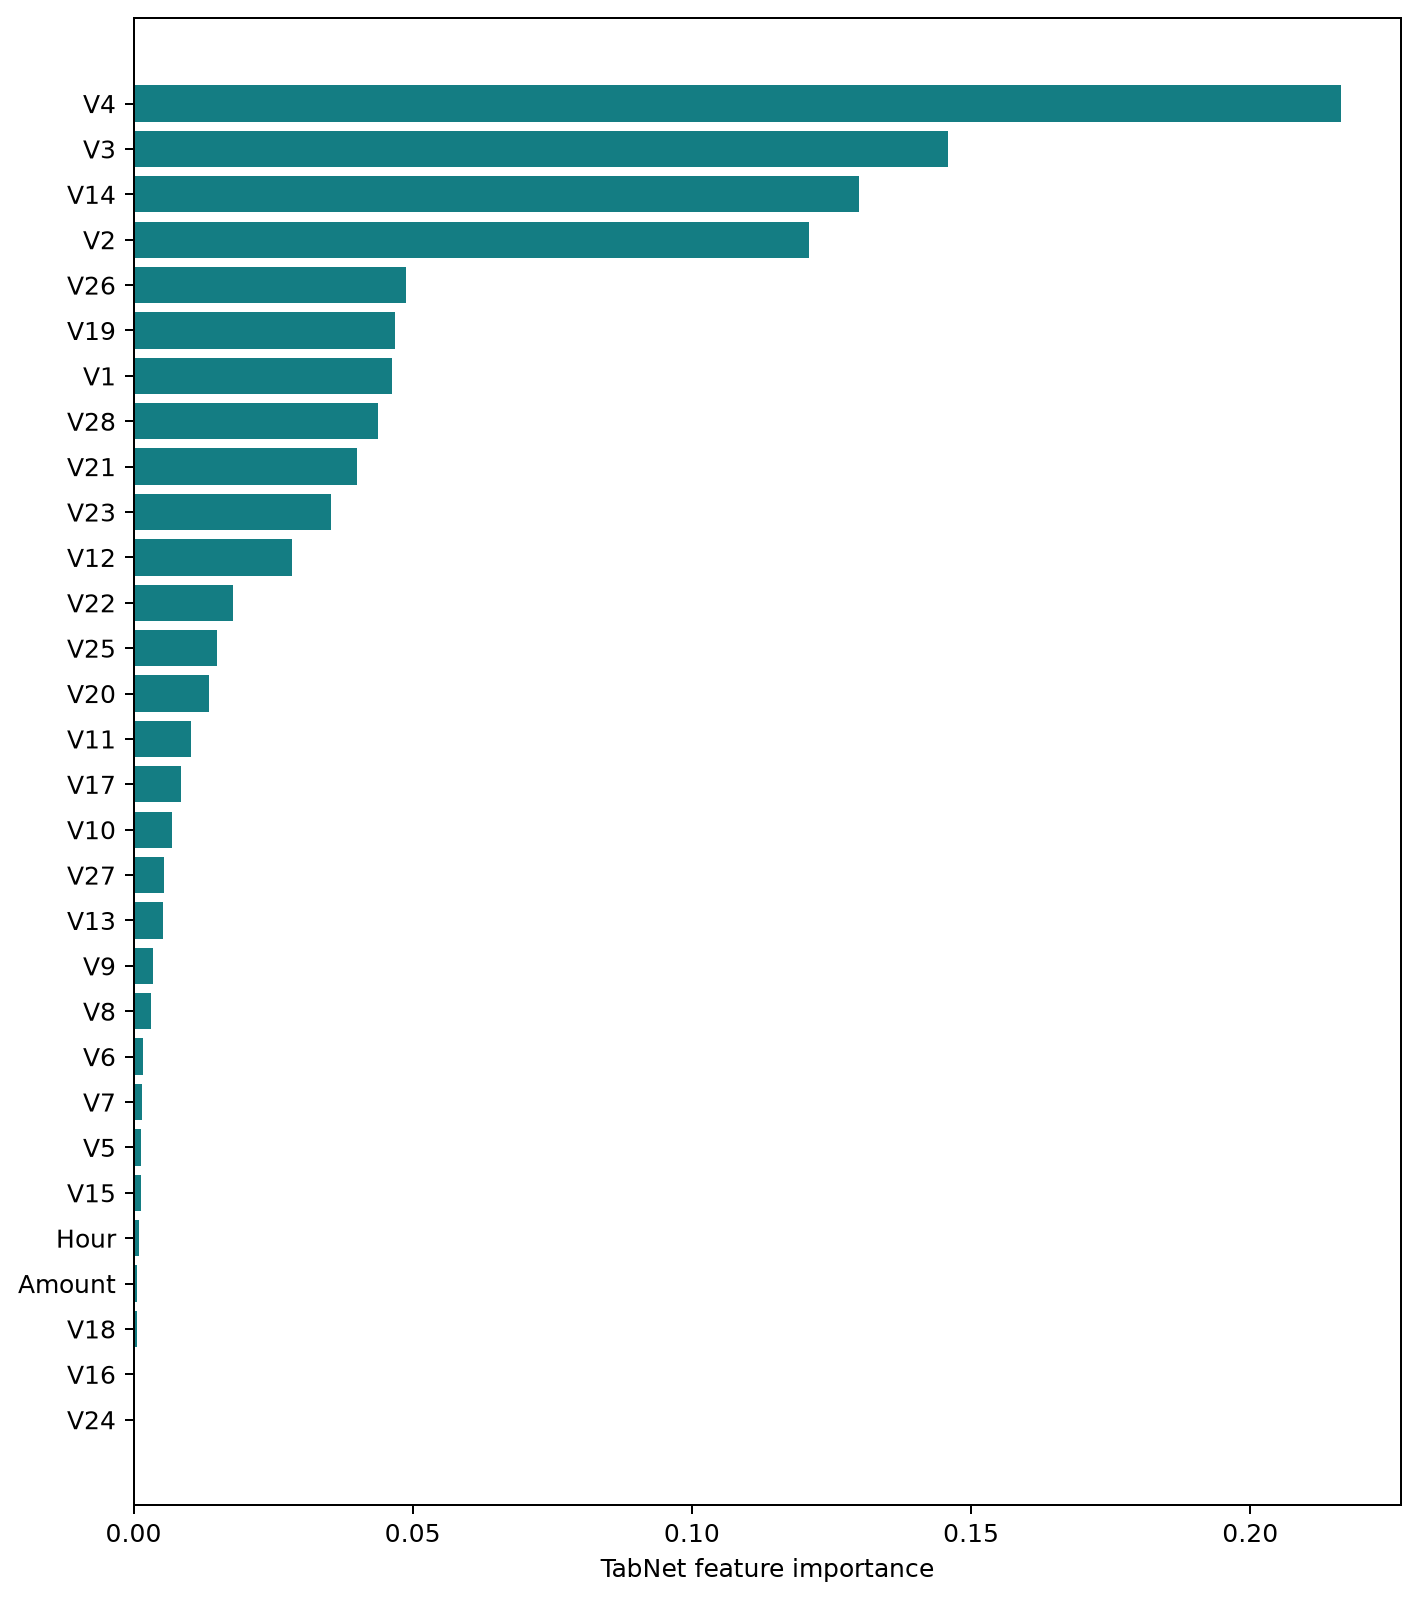

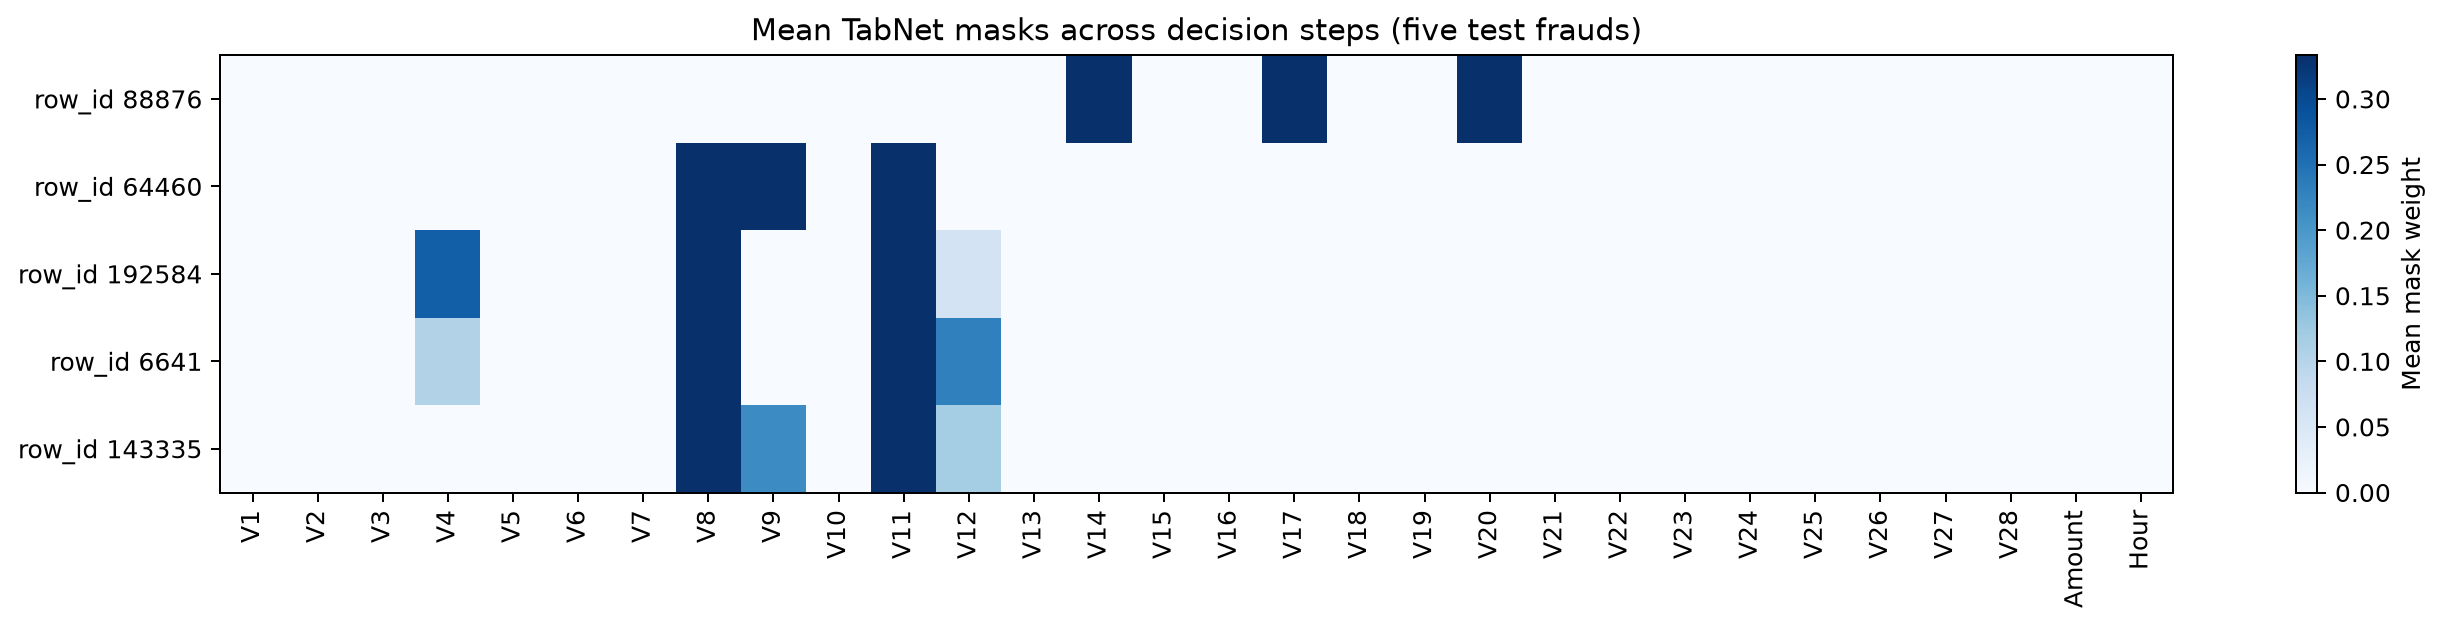

In [2]:
importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": tabnet.feature_importances_,
}).sort_values("importance", ascending=True)

(ROOT / "figures").mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(importance["feature"], importance["importance"], color="#147D83")
ax.set_xlabel("TabNet feature importance")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "tabnet_importance.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

fraud_positions = np.flatnonzero(y_test_np == 1)[:5]
explain_matrix, masks = tabnet.explain(X_test_np[fraud_positions])
mask_stack = np.stack([np.asarray(masks[key]) for key in sorted(masks)], axis=0)
mean_masks = mask_stack.mean(axis=0)
case_ids = np.asarray(row_id_test)[fraud_positions]
fig, ax = plt.subplots(figsize=(15, 3.6))
plot = ax.imshow(mean_masks, aspect="auto", cmap="Blues")
ax.set_xticks(np.arange(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=90)
ax.set_yticks(np.arange(len(case_ids)))
ax.set_yticklabels([f"row_id {value}" for value in case_ids])
ax.set_title("Mean TabNet masks across decision steps (five test frauds)")
fig.colorbar(plot, ax=ax, label="Mean mask weight")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "tabnet_masks.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

pd.DataFrame(explain_matrix, columns=FEATURES, index=case_ids)


In [3]:
def predict_tabnet_prob(X):
    return tabnet.predict_proba(X.loc[:, FEATURES].to_numpy(dtype=np.float32))[:, 1]

tabnet_permutation = permutation_importance(
    predict_tabnet_prob, X_val, y_val, n_repeats=3, random_state=SEED
)
tabnet_permutation.to_csv(ROOT / "results" / "perm_tabnet.csv", index=False)
tabnet_permutation.head(10)


feature,importance_mean,importance_std,baseline_pr_auc
V11,0.222127,0.003328,0.623831
V12,0.169701,0.004113,0.623831
V14,0.122396,0.004050,0.623831
V10,0.058069,0.002555,0.623831
V21,0.031943,0.000813,0.623831
V8,0.028274,0.009053,0.623831
V17,0.024841,0.010685,0.623831
V6,0.018939,0.001789,0.623831
V3,0.017476,0.007843,0.623831
V4,0.014544,0.011164,0.623831
